# 42 · BERT成对推理与真实小预算微调

单元：S12,S13。先修：27、29、33；先读docs/SEARCH_TRAINING_PROTOCOL.md。

来源：[王树森固定目录](https://github.com/wangshusen/SearchEngine/tree/7339c6b126e314abdb74a89adb033d39d8e3d37b)；[Nogueira & Cho 2019](https://arxiv.org/abs/1901.04085v5)；[BERT原论文](https://arxiv.org/abs/1810.04805v2)。这是 Lab 自编实验；王树森后四模块只有公开目录，不称原作者完整讲义。

证据边界：真实SciFact训练分区32/8查询；TinyBERT全参数微调；非中文训练或论文复现。

学习方式：先预测每个对照，再只改一个变量，运行后解释差异。

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display
from reclab.learning.search_curriculum import *

## 双编码与交叉编码
双编码独立编码query/doc可缓存文档向量，交叉编码输入[CLS]query[SEP]doc[SEP]每对重新注意力。前者向量内积约O(Kd)，后者K次Transformer，注意力随pair长度平方增长。检查token_type_ids。

In [2]:
from reclab.search_lessons import models,context
m=models(); ctx=context()
q=sorted(ctx['truth']['train'])[32]
ids=__import__('reclab.retrieval',fromlist=['topk']).topk(ctx['bm25'].score(ctx['queries'][q]),10)
b=m.pair_tokenizer([ctx['queries'][q]]*2,[ctx['texts'][d-1] for d in ids[:2]],padding=True,truncation=True,max_length=96,return_tensors='pt')
print({k:list(v.shape) for k,v in b.items()},'segments',b['token_type_ids'][0].unique().tolist())

/Users/lynnlee/Documents/Codex/2026-10-30/task/soutui-lab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'input_ids': [2, 96], 'token_type_ids': [2, 96], 'attention_mask': [2, 96]} segments [0, 1]


## 截断与batch
固定同一候选，max_length从32改96；query/doc共用pair预算。batch=1和batch=2推理应近似相同，但截断可能改变排名。

In [3]:
import torch
results={}
for length in [32,96]:
    batch=m.pair_tokenizer([ctx['queries'][q]]*2,[ctx['texts'][d-1] for d in ids[:2]],padding=True,truncation=True,max_length=length,return_tensors='pt')
    with torch.inference_mode(): score=m.reranker(**batch).logits[:,0].numpy()
    results[length]=score
    print(length,score)
with torch.inference_mode():
    one=m.reranker(**{k:v[:1] for k,v in batch.items()}).logits[0,0].item()
assert np.isclose(one,results[96][0],atol=1e-5)

32 [  0.90342236 -11.09127   ]
96 [ 7.8716245 -1.0740322]


## 候选预算上限
保持查询与冻结模型不变，仅改变BM25候选深度2/5/10。每次实际交叉编码打分；报告召回正例数、最终NDCG与pair数。重排不能找回候选外的正例，时延仅本机warm批推理。

In [4]:
from reclab.retrieval import metrics
import time
rows=[]
for depth in [2,5,10]:
    candidate=ids[:depth]
    start=time.perf_counter()
    scores=m.rerank(ctx['queries'][q],[ctx['texts'][d-1] for d in candidate])
    order=[candidate[i] for i in np.lexsort((candidate,-scores))]
    truth=ctx['truth']['train'][q]
    rows.append({'depth':depth,'pairs':len(candidate),'known_positive_candidates':len(set(candidate)&set(truth)),
                 'warm_ms':(time.perf_counter()-start)*1000,**metrics({q:order},{q:truth},10)})
display(pd.DataFrame(rows))

,depth,pairs,known_positive_candidates,warm_ms,recall@10,ndcg@10,mrr@10,hit_rate@10
0,2,2,1,5.838958,1.0,1.0,1.0,1.0
1,5,5,1,9.108208,1.0,1.0,1.0,1.0
2,10,10,1,16.775958,1.0,1.0,1.0,1.0


## 真训练
Run All会创建新的workshop run。32 fit / 8 select只来自原train，128 pair以内、2 epoch、CPU、batch8、length96、lr2e−5。正例来自qrels；负例是fit query的BM25未判断文档，可能假负；选择集不强插正例。损失BCEWithLogits不是校准概率。固定预算不看300测试调参。

In [5]:
from reclab.search_training_workshop import run
run_id,result=run()
print('teaching run',run_id,'pairs',result['pairs'],'seconds',result['fit_seconds'])
display(pd.json_normalize(result['rows']))
assert result['encoder_weight_l1_change']>0
print('encoder L1 update',result['encoder_weight_l1_change'],'candidate hit rate',result['candidate_hit_rate'])

teaching run 20261030T142455-38553a49 pairs 128 seconds 1.1206232080003247


,method,select.recall@10,select.ndcg@10,select.mrr@10,select.hit_rate@10
0,frozen_tinybert,0.833333,0.805515,0.8125,0.875
1,finetuned_tinybert,0.833333,0.805515,0.8125,0.875


encoder L1 update 1.8691143989562988 candidate hit rate 0.875


## 训练曲线和候选上限
训练loss下降不保证select排序提高；未召回正例无法重排救回。保存checkpoint和预测在同一registry，正式latest不变。练习先估计将候选10改20的计算量，不用select结果反复搜索配方。

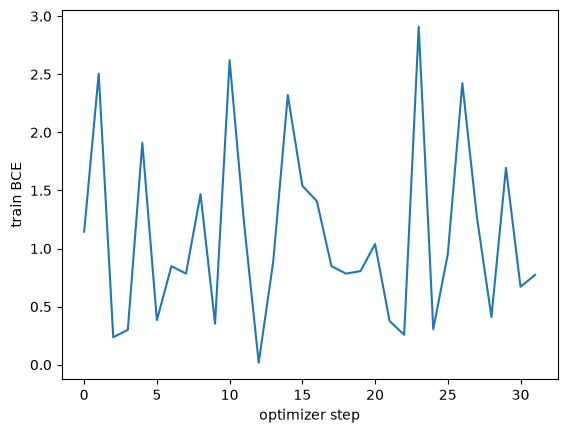

Tiny selected training subset; pretraining overlap unknown; unjudged are not verified negative; fixed top10 candidate ceiling; not paper reproduction or calibrated relevance probability.


In [6]:
import matplotlib.pyplot as plt
plt.plot(result['losses']); plt.xlabel('optimizer step'); plt.ylabel('train BCE'); plt.show()
from reclab.search import latest
assert latest()[0]['run_id']==ctx['receipt']['run_id']
print(result['limits'])

## 本次保存结果的解读

当前固定运行中冻结与微调的select NDCG@10均约0.806、MRR@10均0.8125，未出现排序改善。attention query权重L1确实变化，说明真实训练发生；它不证明泛化提升。候选hit rate为0.875，而宏平均正例recall@10约0.833，两者分母不同。单查询候选2/5/10均已有正例，扩大预算只增加本次推理成本，没有质量改善。

改参数后应以新输出重新判断，不把这段固定解读当作新的测量。

## 复盘与练习

写下输入、输出、保持不变的量与本章不能支持的结论。选一个上面的单变量参数先预测再重跑；保留失败例。回到搜索学习路径继续下一语义单元。